# Inspect data and establish a baseline

This notebook loads the local Telco Customer Churn CSV, checks its quality and categorical values, and explores churn patterns. It then cleans `TotalCharges`, trains a class-balanced logistic-regression baseline, examines feature coefficients, and saves held-out predictions for later comparison with the LLM experiment.

Run the cells in order. The raw customer dataset is local and gitignored; the model's test-set outputs are written under `data/processed/`.

In [9]:
from pathlib import Path
import pandas as pd

working_dir = Path.cwd()
project_root = working_dir.parent if working_dir.name == "notebooks" else working_dir
csv_path = project_root / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(csv_path)

print("Shape:", df.shape)
print("Columns:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)


Shape: (7043, 21)
Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


## Inspect rows and basic data quality

The dataset load above establishes its shape and schema. The next check previews five records, counts missing values per field, and counts fully duplicated rows so data issues are visible before feature analysis.

In [10]:
print("First 5 rows:")
display(df.head())

print("\nMissing values by column:")
print(df.isna().sum())

print("\nDuplicate rows across all columns:", df.duplicated().sum())

First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Missing values by column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows across all columns: 0


## Review low-cardinality fields

This cell lists distinct values for every column with fewer than ten values, including missing values when counting. It helps identify category labels, binary options, and special values that need deliberate preprocessing.

In [11]:
print("Unique values for columns with fewer than 10 unique values (including missing values):")
for column in df.columns:
    unique_count = df[column].nunique(dropna=False)
    if unique_count < 10:
        print(f"\n{column} ({unique_count} unique values):")
        print(df[column].drop_duplicates().tolist())

Unique values for columns with fewer than 10 unique values (including missing values):

gender (2 unique values):
['Female', 'Male']

SeniorCitizen (2 unique values):
[0, 1]

Partner (2 unique values):
['Yes', 'No']

Dependents (2 unique values):
['No', 'Yes']

PhoneService (2 unique values):
['No', 'Yes']

MultipleLines (3 unique values):
['No phone service', 'No', 'Yes']

InternetService (3 unique values):
['DSL', 'Fiber optic', 'No']

OnlineSecurity (3 unique values):
['No', 'Yes', 'No internet service']

OnlineBackup (3 unique values):
['Yes', 'No', 'No internet service']

DeviceProtection (3 unique values):
['No', 'Yes', 'No internet service']

TechSupport (3 unique values):
['No', 'Yes', 'No internet service']

StreamingTV (3 unique values):
['No', 'Yes', 'No internet service']

StreamingMovies (3 unique values):
['No', 'Yes', 'No internet service']

Contract (3 unique values):
['Month-to-month', 'One year', 'Two year']

PaperlessBilling (2 unique values):
['Yes', 'No']

PaymentM

## Convert total charges safely

`TotalCharges` may contain blank strings even though the field is numeric in meaning. Coercion converts those entries to `NaN`; the cell reports and displays affected records without deciding whether they should be dropped or imputed. The later model pipeline handles missing numeric features using its training-set median imputer.

In [18]:
# Convert TotalCharges to numeric, turning unparseable values into NaN.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

invalid_total_charges = df["TotalCharges"].isna()
print("Rows with TotalCharges converted to NaN:", int(invalid_total_charges.sum()))
print("Full rows with NaN TotalCharges:")
display(df.loc[invalid_total_charges])

Rows with TotalCharges converted to NaN: 11
Full rows with NaN TotalCharges:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureBucket,MonthlyChargesQuartile
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No,0-12 months,Q2
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No,0-12 months,Q1
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No,0-12 months,Q3
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No,0-12 months,Q1
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No,0-12 months,Q2
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No,0-12 months,Q1
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No,0-12 months,Q1
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No,0-12 months,Q1
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No,0-12 months,Q1
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,No,Two year,No,Mailed check,73.35,NaN,No,0-12 months,Q3


## Explore churn rates

These charts compare the observed proportion of churners across contract types, predefined tenure bands, and quartiles of monthly charges. They are descriptive group summaries, not causal estimates or model predictions.

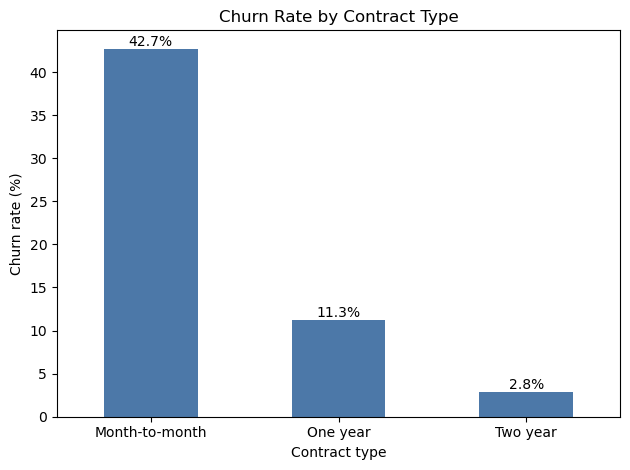

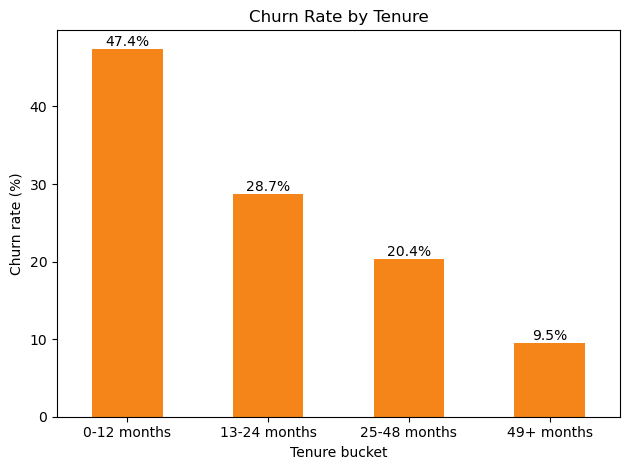

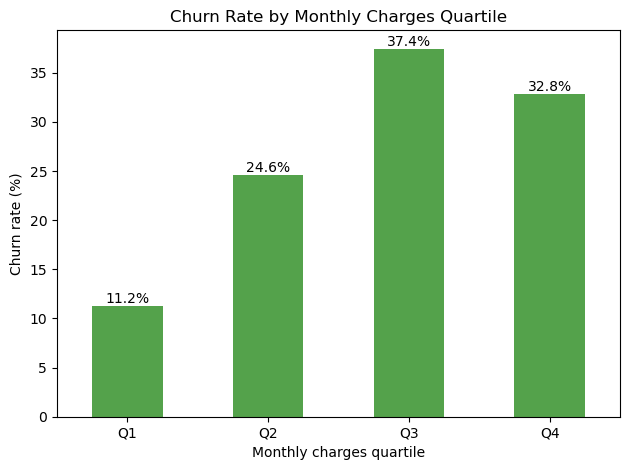

Contract churn rates (%):
 Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

Tenure-bucket churn rates (%):
 TenureBucket
0-12 months     47.44
13-24 months    28.71
25-48 months    20.39
49+ months       9.51
Name: Churn, dtype: float64

Monthly-charge quartile churn rates (%):
 MonthlyChargesQuartile
Q1    11.24
Q2    24.65
Q3    37.44
Q4    32.82
Name: Churn, dtype: float64


In [19]:
import matplotlib.pyplot as plt

churn_flag = df["Churn"].eq("Yes")

# Churn rate by contract type.
contract_order = ["Month-to-month", "One year", "Two year"]
contract_churn_rate = (
    df.groupby("Contract")["Churn"]
    .apply(lambda values: values.eq("Yes").mean() * 100)
    .reindex(contract_order)
)
ax = contract_churn_rate.plot(kind="bar", color="#4C78A8", rot=0)
ax.set(title="Churn Rate by Contract Type", xlabel="Contract type", ylabel="Churn rate (%)")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.tight_layout()
plt.show()

# Churn rate by tenure bucket.
tenure_labels = ["0-12 months", "13-24 months", "25-48 months", "49+ months"]
df["TenureBucket"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, float("inf")],
    labels=tenure_labels,
)
tenure_churn_rate = (
    df.groupby("TenureBucket", observed=False)["Churn"]
    .apply(lambda values: values.eq("Yes").mean() * 100)
    .reindex(tenure_labels)
)
ax = tenure_churn_rate.plot(kind="bar", color="#F58518", rot=0)
ax.set(title="Churn Rate by Tenure", xlabel="Tenure bucket", ylabel="Churn rate (%)")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.tight_layout()
plt.show()

# Churn rate by MonthlyCharges quartile (rank first keeps tied values in exactly four groups).
df["MonthlyChargesQuartile"] = pd.qcut(
    df["MonthlyCharges"].rank(method="first"),
    q=4,
    labels=["Q1", "Q2", "Q3", "Q4"],
)
monthly_charges_churn_rate = (
    df.groupby("MonthlyChargesQuartile", observed=False)["Churn"]
    .apply(lambda values: values.eq("Yes").mean() * 100)
    .reindex(["Q1", "Q2", "Q3", "Q4"])
)
ax = monthly_charges_churn_rate.plot(kind="bar", color="#54A24B", rot=0)
ax.set(title="Churn Rate by Monthly Charges Quartile", xlabel="Monthly charges quartile", ylabel="Churn rate (%)")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.tight_layout()
plt.show()

print("Contract churn rates (%):\n", contract_churn_rate.round(2))
print("\nTenure-bucket churn rates (%):\n", tenure_churn_rate.round(2))
print("\nMonthly-charge quartile churn rates (%):\n", monthly_charges_churn_rate.round(2))

## Rank feature associations with churn

The following tests measure univariate association with the `Churn` label: point-biserial correlation for numeric features and chi-square with Cramér's V for categorical features. Strengths are ranked by absolute correlation or Cramér's V; these are screening statistics, not causal effects or adjusted model importances.

In [17]:
from scipy.stats import chi2_contingency, pointbiserialr

association_rows = []
numeric_features = {"tenure", "MonthlyCharges", "TotalCharges"}
excluded_features = {"customerID", "Churn", "TenureBucket", "MonthlyChargesQuartile"}

for feature in df.columns:
    if feature in excluded_features:
        continue

    paired = df[[feature, "Churn"]].dropna()
    if paired[feature].nunique() < 2 or paired["Churn"].nunique() < 2:
        continue

    if feature in numeric_features:
        coefficient, p_value = pointbiserialr(
            paired["Churn"].eq("Yes").astype(int),
            paired[feature].astype(float),
        )
        association_rows.append(
            {
                "feature": feature,
                "test": "point-biserial",
                "association_strength": abs(float(coefficient)),
                "signed_r": float(coefficient),
                "p_value": float(p_value),
                "n": len(paired),
            }
        )
    else:
        contingency = pd.crosstab(paired[feature], paired["Churn"])
        chi2, p_value, _, _ = chi2_contingency(contingency)
        n = int(contingency.to_numpy().sum())
        min_dimension = min(contingency.shape[0] - 1, contingency.shape[1] - 1)
        cramers_v = (chi2 / (n * min_dimension)) ** 0.5 if min_dimension > 0 else 0.0
        association_rows.append(
            {
                "feature": feature,
                "test": "chi-square (Cramer's V)",
                "association_strength": float(cramers_v),
                "signed_r": float("nan"),
                "p_value": float(p_value),
                "n": n,
            }
        )

association_results = (
    pd.DataFrame(association_rows)
    .sort_values("association_strength", ascending=False)
    .reset_index(drop=True)
)
print("Top 5 features by association strength with Churn:")
display(association_results.head(5).round({"association_strength": 4, "signed_r": 4, "p_value": 6}))

Top 5 features by association strength with Churn:


,feature,test,association_strength,signed_r,p_value,n
0,Contract,chi-square (Cramer's V),0.4101,NaN,0.0,7043
1,tenure,point-biserial,0.3522,-0.3522,0.0,7043
2,OnlineSecurity,chi-square (Cramer's V),0.3474,NaN,0.0,7043
3,TechSupport,chi-square (Cramer's V),0.3429,NaN,0.0,7043
4,InternetService,chi-square (Cramer's V),0.3225,NaN,0.0,7043


## Train and evaluate the logistic-regression baseline

The model excludes `customerID` and the target from its inputs, stratifies the 80/20 split on churn, and uses `random_state=42`. A preprocessing pipeline imputes and scales numeric features and imputes/one-hot-encodes categorical features; the classifier uses balanced class weights. Test metrics and the confusion matrix summarize held-out performance.

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Keep identifiers for the prediction export, but never use them as model features.
X = df.drop(columns=["customerID", "Churn", "TenureBucket", "MonthlyChargesQuartile"], errors="ignore")
y = df["Churn"]
customer_ids = df["customerID"]

categorical_columns = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
# Treat low-cardinality numeric fields such as SeniorCitizen as categorical.
categorical_columns += [
    column
    for column in X.select_dtypes(include="number").columns
    if X[column].nunique(dropna=False) <= 2
]
numeric_columns = [column for column in X.select_dtypes(include="number").columns if column not in categorical_columns]

X_train, X_test, y_train, y_test, customer_ids_train, customer_ids_test = train_test_split(
    X,
    y,
    customer_ids,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                ]
            ),
            numeric_columns,
        ),
        (
            "categorical",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore")),
                ]
            ),
            categorical_columns,
        ),
    ],
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42)),
    ]
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f"Train rows: {len(X_train)}; test rows: {len(X_test)}")
print(f"Categorical features one-hot encoded: {categorical_columns}")
print(f"Numeric features: {numeric_columns}")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, pos_label='Yes'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, pos_label='Yes'):.4f}")
print(f"F1:        {f1_score(y_test, y_pred, pos_label='Yes'):.4f}")
print("Confusion matrix (rows=actual, columns=predicted; labels No, Yes):")
print(confusion_matrix(y_test, y_pred, labels=["No", "Yes"]))

Train rows: 5634; test rows: 1409
Categorical features one-hot encoded: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'SeniorCitizen']
Numeric features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Accuracy:  0.7374
Precision: 0.5034
Recall:    0.7834
F1:        0.6130
Confusion matrix (rows=actual, columns=predicted; labels No, Yes):
[[746 289]
 [ 81 293]]


## Inspect model coefficients

The fitted logistic-regression coefficients show the direction and magnitude of each encoded feature's contribution to the model's log-odds. Numeric inputs are standardized, so their coefficients are per standard-deviation change. Categorical coefficients correspond to one-hot indicators and should be interpreted as model associations, not causal effects.

In [22]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
coefficients = model.named_steps["classifier"].coef_.ravel()
coefficient_ranking = pd.DataFrame(
    {
        "feature": feature_names,
        "coefficient": coefficients,
        "absolute_coefficient": abs(coefficients),
    }
).sort_values("absolute_coefficient", ascending=False)

print("Top 10 encoded features by absolute logistic-regression coefficient:")
display(coefficient_ranking.head(10).reset_index(drop=True).round(4))

Top 10 encoded features by absolute logistic-regression coefficient:


,feature,coefficient,absolute_coefficient
0,numeric__tenure,-1.1373,1.1373
1,categorical__Contract_Two year,-0.7788,0.7788
2,categorical__InternetService_Fiber optic,0.7170,0.7170
3,numeric__MonthlyCharges,-0.6772,0.6772
4,categorical__Contract_Month-to-month,0.6682,0.6682
5,categorical__InternetService_DSL,-0.6195,0.6195
6,numeric__TotalCharges,0.4722,0.4722
7,categorical__StreamingMovies_Yes,0.2831,0.2831
8,categorical__StreamingTV_No internet service,-0.2704,0.2704
9,categorical__InternetService_No,-0.2704,0.2704


## Save held-out baseline predictions

This final baseline step joins predictions back to the held-out customer identifiers locally and records the actual label, predicted label, and probability assigned to churn. The saved file is the shared test-set reference for later LLM comparisons; identifiers are not model inputs.

In [24]:
positive_class_index = list(model.named_steps["classifier"].classes_).index("Yes")
y_probability = model.predict_proba(X_test)[:, positive_class_index]

predictions = pd.DataFrame(
    {
        "customerID": customer_ids_test.to_numpy(),
        "actual_churn": y_test.to_numpy(),
        "baseline_predicted": y_pred,
        "baseline_probability": y_probability,
    }
)
output_path = project_root / "data" / "processed" / "baseline_predictions.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)
predictions.to_csv(output_path, index=False)
print(f"Saved {len(predictions)} test-set predictions to {output_path}")
display(predictions.head())

Saved 1409 test-set predictions to data\processed\baseline_predictions.csv


,customerID,actual_churn,baseline_predicted,baseline_probability
0,4376-KFVRS,No,No,0.115401
1,2754-SDJRD,No,Yes,0.852097
2,9917-KWRBE,No,No,0.146041
3,0365-GXEZS,No,Yes,0.661149
4,9385-NXKDA,No,No,0.059847
